In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv('Salary_dataset.csv')
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [ ]:
def compute_cost(x_train,y_train,w,b):
    m=len(x_train)
    cost=0
    for i in range(m):
        f=w*x_train[i]+b
        error=f-y_train[i]
        cost+=error**2
    
    cost=cost/(2*m)
    return cost

In [ ]:
def compute_gradient(x,y,w,b):
    m=len(x)
    dj_dw=0
    dj_db=0
    for i in range(m):
        f=w*x[i]+b
        error=f-y[i]
        dj_dw+=error*x[i]
        dj_db+=error
    dj_dw=dj_dw/m
    dj_db=dj_db/m

    return dj_dw, dj_db


In [76]:
def gradient_descent(x,y,w,b,alpha,epoch):
    cost_history=[]  
    #alpha is the learning rate here
    
    for i in range(epoch):
        dw_dj,dw_db=compute_gradient(x,y,w,b)
        w=w-alpha*dw_dj
        b=b-alpha*dw_db
        cost=compute_cost(x,y,w,b)
        cost_history.append(cost)
    
    return w,b,cost_history

In [77]:
X=df['YearsExperience'].to_numpy()
Y=df['Salary'].to_numpy()
w=0
b=0
alpha=0.01
epoch=2000
w,b,cost_history=gradient_descent(X,Y,w,b,alpha,epoch)

print('w and b after learning :',w,b)
y_pred=w*X+b

w and b after learning : 9505.03435910129 24472.969763833225


In [78]:
from sklearn.metrics import r2_score

print("R2 Score:", r2_score(Y, y_pred))

R2 Score: 0.9569159787361847


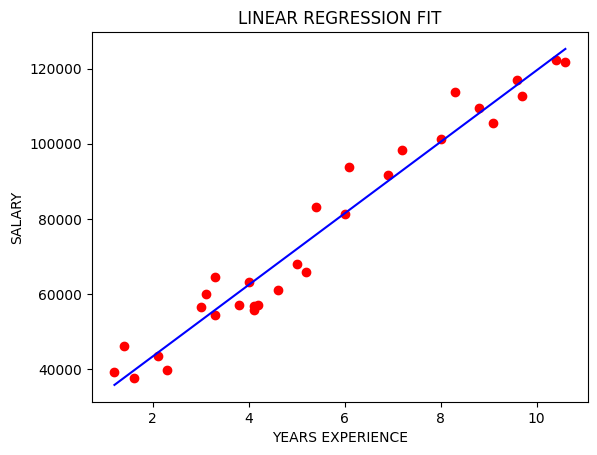

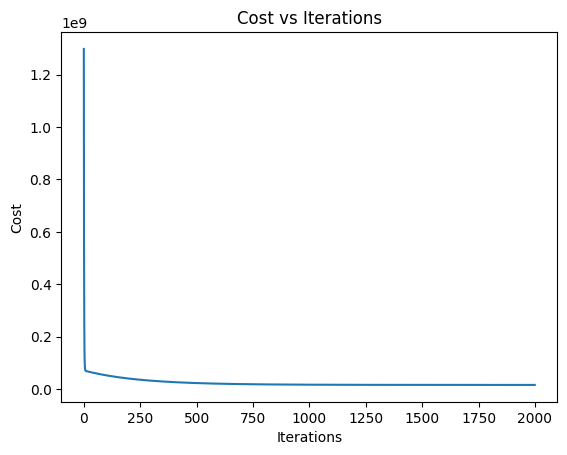

In [79]:
plt.figure()
plt.scatter(X,Y,color='r',label='training data')
plt.plot(X,y_pred,color='b',label='fit')
plt.xlabel('YEARS EXPERIENCE')
plt.ylabel('SALARY')
plt.title('LINEAR REGRESSION FIT')
plt.plot()

plt.figure()
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost vs Iterations")
plt.show()